# Sabotage Connectome

Compares two connectome-based source reconstruction solvers -- `wCSET` (`harmonic_method="lowpass"`, `harm=5`, the value settled on in `harmonic-prior-tuning.ipynb`) and `CSET` (per-timepoint iterative L1 solve, `lambda2=0.1`) -- against 3 independent connectome corruption methods (`swap`, `brutal`, `dmri`; see the "Three corruption methods" section) at increasing severity, evaluated against `simf10`'s known ground truth (`gold`).

Reconstruction is restricted to just the half-rising-phase and peak-phase timepoints (`hrp`/`pp`): both solvers process each timepoint fully independently (no temporal coupling -- see their `solve()` implementations), so this is a real cost reduction, not an approximation, and it matters a lot for `CSET` specifically, whose per-timepoint iterative L1 optimization is far more expensive than `wCSET`'s single linear solve.

**First pass**: `n_repeats=1`, `percentages=[0, 50, 100]`, specifically to measure how long this actually takes before committing to the full study (more repeats, finer percentage grid). Timing is printed at the end of the sweep cell.

## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `con`: Structural connectome (raw, before any weight transform or sabotage)
- `gold`: Ground truth
- `eig`: Precomputed eigendecomposition of the clean connectome (reused at `percentage=0`, where every corruption method is a no-op)

In [1]:
# imports
import time
import numpy as np
import pandas as pd
from tqdm import tqdm

import mindmap as mm
import mne

from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
run = "1"

# data
fwd = dm.load(sub, "fwd", desc="inv")
ave = dm.load(sub, "ave", run=run)
ncov = dm.load(sub, "cov", run=run)
con = dm.load(sub, "con")
gold = dm.load(sub, "gold", run=run)
eig = dm.load(sub, "eig")

# crop
tmin, tmax = -0.05, 0.15

## 🧬 - Data Processing

Regularization parameter (`wCSET` only -- `CSET` uses a fixed `lambda2=0.1`, not an
SNR-based estimate, per the request), then reduce `data`/`ground` down to just the
`hrp`/`pp` timepoints (see the title cell for why that's valid here).

In [2]:
snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
lambda2_wcset = max(0.01, 1.0 / (snr.max()**2))
lambda2_cset = 0.1

print(f"Estimated SNR: {snr.max():.3f}")
print(f"lambda2_wcset: {lambda2_wcset:.3f}  lambda2_cset: {lambda2_cset}")

    Created an SSP operator (subspace dimension = 1)


Computing rank from covariance with rank=None


    Using tolerance 4e-15 (2.2e-16 eps * 203 dim * 0.088  max singular value)


    Estimated rank (eeg): 202


    EEG: rank 202 computed from 203 data channels with 1 projector


    Setting small EEG eigenvalues to zero (without PCA)


    Created the whitener using a noise covariance matrix with rank 202 (1 small eigenvalues omitted)


Estimated SNR: 27.670


lambda2_wcset: 0.010  lambda2_cset: 0.1


In [3]:
data = ave.copy().crop(tmin=tmin, tmax=tmax)
ground = gold.copy().crop(tmin=tmin, tmax=tmax)

hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)[0]
pp = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]

# Reduce to just the 2 timepoints we actually solve/evaluate at. Both solvers'
# solve() process each timepoint independently (a batched linear op for wCSET,
# an explicit per-timepoint loop for CSET) -- neither uses the *value* of
# evoked.times, only evoked.data's columns, so a fake tmin/tstep here doesn't
# affect the computed reconstruction, only cosmetic labels on the output stc
# we don't rely on (we index by position: 0=hrp, 1=pp).
data_2pt = mne.EvokedArray(data.data[:, [hrp, pp]], data.info, tmin=0, nave=data.nave, comment="hrp_pp")
ground_2pt = mm.analysis.inverse.make_stc(fwd["src"], ground.data[:, [hrp, pp]], tmin=0, tstep=1)

# Weight inversion (length -> strength) is a semantic decision about what
# the connectome's weights mean, not part of compute_cst's job.
con_strength = np.divide(1, con, out=np.zeros_like(con), where=con > 0)
source_space = fwd["src"]

# true seed region + coordinates, for peak localization error at hrp
src_seed = dm.load(sub, "source", run=run)
simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub}"/"simulator")
true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

## 🎚️ - Three corruption methods, calibrated to a common severity axis

Unchanged from the earlier version of this notebook (see chat history for the full
reasoning): `swap` (`swap_rewire_connectome`, degree/edge-count-preserving, needs
empirical calibration since its swap-count -> corruption curve saturates below 100%
and isn't linear), `brutal` (`perturb_connectome_topology`, uniform sampling, exact
closed-form severity), and `dmri` (`perturb_connectome_topology` again, now with
distance-biased sampling weights mimicking real tractography error structure).

In [4]:
percentages = [0, 20, 40, 60, 80, 100]
n_repeats = 1
methods = ["swap", "brutal", "dmri"]
DMRI_ADDITION_RATIO = 2   # additions:deletions -- see markdown above

triu_idx = np.triu_indices_from(con_strength, k=1)
orig_vals = con_strength[triu_idx]
orig_edges = orig_vals != 0
total = int(orig_edges.sum())

# --- swap: probe a swap-count grid, invert the curve to hit pct/100 * ceiling.
def measure_swap_binary_frac(mult, seed=0):
    n_swaps = round(mult * total / 2)
    rewired = mm.analysis.connectivity.swap_rewire_connectome(con_strength, n_swaps=n_swaps, seed=seed)
    return ((rewired[triu_idx] != 0) & ~orig_edges).sum() / total

mult_grid = np.array([0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1, 1.5, 2, 3, 4, 5, 7, 10, 13, 16, 20, 25, 30])
probe_fracs = np.array([measure_swap_binary_frac(mult) for mult in mult_grid])
probe_fracs_mono = np.maximum.accumulate(probe_fracs)  # enforce monotonic, needed for interpolation
swap_ceiling = probe_fracs_mono[-1]

calibrated_n_swaps = {0: 0}
for percentage in percentages[1:]:
    target_frac = percentage / 100 * swap_ceiling
    mult = np.interp(target_frac, probe_fracs_mono, mult_grid)
    calibrated_n_swaps[percentage] = round(mult * total / 2)

# --- brutal / dmri: exact closed form, no probing needed (see markdown above).
brutal_counts = {p: round(p / 100 * total) for p in percentages}
dmri_counts = {p: (round(brutal_counts[p] / DMRI_ADDITION_RATIO), brutal_counts[p]) for p in percentages}  # (n_deletions, n_additions)

deletion_weights, addition_weights = mm.analysis.connectivity.dmri_uncertainty_weights_from_source_space(con_strength, source_space)

print(f"swap_rewire_connectome empirical ceiling (treated as '100%'): {swap_ceiling:.4f}")
print(f"calibrated n_swaps per severity level: {calibrated_n_swaps}")
print(f"brutal n_deletions=n_additions per severity level: {brutal_counts}")
print(f"dmri (n_deletions, n_additions) per severity level: {dmri_counts}")


def corrupt(method, percentage, seed):
    if method == "swap":
        return mm.analysis.connectivity.swap_rewire_connectome(con_strength, n_swaps=calibrated_n_swaps[percentage], seed=seed)
    if method == "brutal":
        k = brutal_counts[percentage]
        return mm.analysis.connectivity.perturb_connectome_topology(con_strength, n_deletions=k, n_additions=k, seed=seed)
    if method == "dmri":
        n_del, n_add = dmri_counts[percentage]
        return mm.analysis.connectivity.perturb_connectome_topology(
            con_strength, n_deletions=n_del, n_additions=n_add,
            deletion_weights=deletion_weights, addition_weights=addition_weights, seed=seed,
        )
    raise ValueError(f"unknown method {method!r}")

swap_rewire_connectome empirical ceiling (treated as '100%'): 0.9890
calibrated n_swaps per severity level: {0: 0, 20: 24335, 40: 55744, 60: 101659, 80: 182560, 100: 3274785}
brutal n_deletions=n_additions per severity level: {0: 0, 20: 43664, 40: 87328, 60: 130991, 80: 174655, 100: 218319}
dmri (n_deletions, n_additions) per severity level: {0: (0, 0), 20: (21832, 43664), 40: (43664, 87328), 60: (65496, 130991), 80: (87328, 174655), 100: (109160, 218319)}


## 💥 - Reconstruction sweep

For each `methods` x `percentages` x `n_repeats`: corrupt the connectome once and
compute its eigendecomposition once (reused for *both* solvers -- `CSET` only needs
`eigenvectors`, no separate decomposition), then solve with `wCSET` (`harmonic_method=
"lowpass"`, `harm=5`) and `CSET` (`lambda2=0.1`) on the reduced `hrp`/`pp` data.
Registered under `label=f"{solver}_{method}"` (6 series total), `coord="percentage"`.

Per-phase timing (`compute_cst` vs. each solver's `solve()`) is tracked and printed at
the end -- the actual point of this first pass.

In [5]:
metrics = mm.metric.MetricSuite(f"Sabotage Connectome {sub}")
scalar_rows = []

eigvec_clean, eigval_clean = eig["vec"], eig["val"]

n_eig_real = 0
eig_time_total = 0.0
solve_time = {"wcset": 0.0, "cset": 0.0}
n_solves = {"wcset": 0, "cset": 0}

t_start = time.time()

for method in methods:
    for percentage in tqdm(percentages, desc=f"{method} severity levels"):
        for repeat in range(n_repeats):
            if percentage == 0:
                eigvec, eigval = eigvec_clean, eigval_clean
            else:
                t0 = time.time()
                sabotaged = corrupt(method, percentage, repeat)
                eigvec, eigval = mm.analysis.connectivity.compute_cst(sabotaged)
                eig_time_total += time.time() - t0
                n_eig_real += 1

            solvers = {
                "wcset": lambda: mm.analysis.inverse.wCSET(
                    forward = fwd, noise_cov = ncov, depth = 0.5,
                    eigenvectors = eigvec, eigenvalues = eigval,
                    harm = 5, harmonic_method = "lowpass",
                ).solve(data_2pt, lambda2_wcset),
                "cset": lambda: mm.analysis.inverse.CSET(
                    forward = fwd, noise_cov = ncov, depth = 0.5,
                    eigenvectors = eigvec,
                ).solve(data_2pt, lambda2=lambda2_cset),
            }

            for solver_name, run_solver in solvers.items():
                t1 = time.time()
                sol = run_solver()
                solve_time[solver_name] += time.time() - t1
                n_solves[solver_name] += 1

                label = f"{solver_name}_{method}"

                corr = np.asarray(mm.analysis.inverse.compute_stc_correlation(ground_2pt, sol, mode="spatial", method="pearson"))

                pr_hrp = mm.core.calc_pr_curve(ground_2pt.data[:, 0] > 0, sol.data[:, 0])
                pr_pp = mm.core.calc_pr_curve(ground_2pt.data[:, 1] > 0, sol.data[:, 1])

                hit_hrp = find_peak_localization_error(sol.data[:, 0], true_source_mask, dipole_positions)

                for metric_name, value in [
                    ("correlation_hrp", corr[0]),
                    ("correlation_pp", corr[1]),
                    ("ap_hrp", pr_hrp["ap"]),
                    ("ap_pp", pr_pp["ap"]),
                    ("localization_error_hrp", hit_hrp["distance_mm"]),
                ]:
                    metrics.register(label, metric_name, float(value), percentage=percentage)

                scalar_rows.append(dict(
                    solver = solver_name, method = method, percentage = percentage, repeat = repeat,
                    corr_hrp = float(corr[0]), corr_pp = float(corr[1]),
                    ap_hrp = pr_hrp["ap"], ap_pp = pr_pp["ap"],
                    loc_err_hrp = hit_hrp["distance_mm"],
                ))

total_time = time.time() - t_start
scalar_df = pd.DataFrame(scalar_rows)

print(f"\nTotal wall time: {total_time:.1f}s")
print(f"Real eigendecompositions: {n_eig_real}, {eig_time_total:.1f}s total, {eig_time_total/max(n_eig_real,1):.1f}s avg")
for name in ["wcset", "cset"]:
    print(f"{name}: {n_solves[name]} solves, {solve_time[name]:.1f}s total, {solve_time[name]/max(n_solves[name],1):.2f}s avg")


swap severity levels:   0%|          | 0/6 [00:00<?, ?it/s]


swap severity levels:  17%|█▋        | 1/6 [00:04<00:24,  4.87s/it]


swap severity levels:  33%|███▎      | 2/6 [00:23<00:51, 12.77s/it]


swap severity levels:  50%|█████     | 3/6 [00:47<00:54, 18.14s/it]


swap severity levels:  67%|██████▋   | 4/6 [01:08<00:38, 19.38s/it]


swap severity levels:  83%|████████▎ | 5/6 [01:30<00:19, 19.99s/it]

... (15 outputs left out)


dmri severity levels:  83%|████████▎ | 5/6 [01:32<00:20, 20.75s/it]


dmri severity levels: 100%|██████████| 6/6 [01:51<00:00, 20.33s/it]


dmri severity levels: 100%|██████████| 6/6 [01:51<00:00, 18.64s/it]


Total wall time: 334.3s
Real eigendecompositions: 15, 264.8s total, 17.7s avg
wcset: 18 solves, 22.8s total, 1.27s avg
cset: 18 solves, 46.5s total, 2.58s avg


## 📊 - Visualization

Correlation (hrp/pp), average precision (hrp/pp), and peak-localization-error (hrp) vs.
connectome corruption severity, one colored line per `{solver}_{method}` combination.

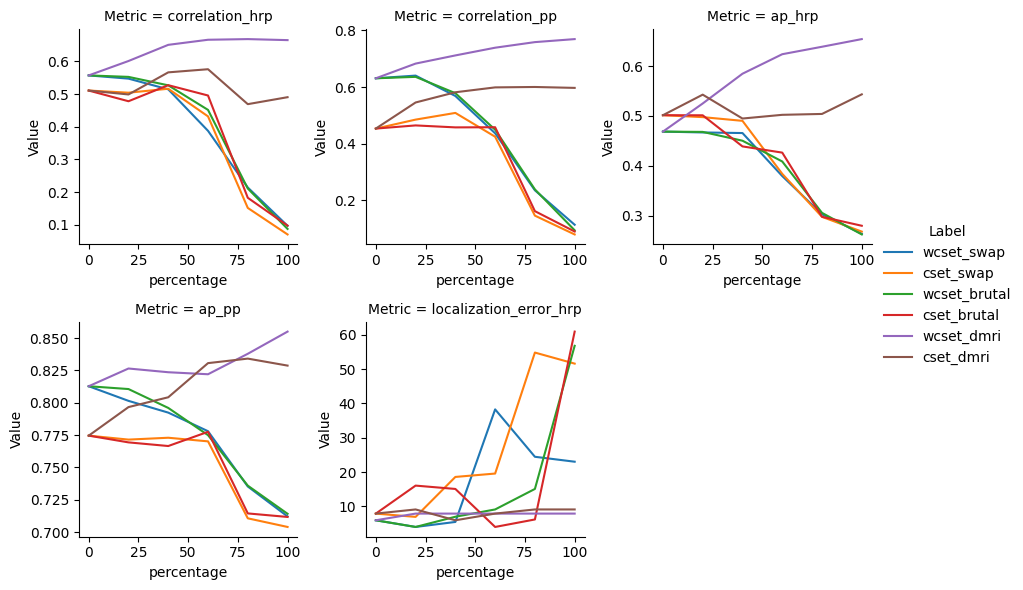

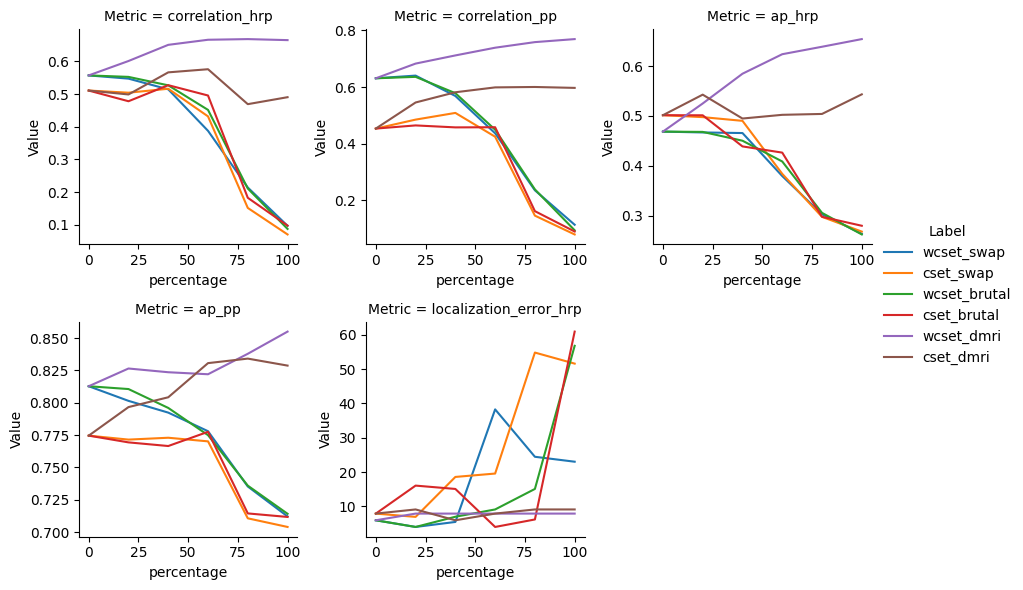

In [ ]:
metrics.plot(
    metrics = ["correlation_hrp", "correlation_pp", "ap_hrp", "ap_pp", "localization_error_hrp"],
    coord = "percentage",
    kind = "line",
);